# Task 3 · Feature Engineering
**PowerCo SME churn (BCG X Data Science Job Simulation, Forage)**

The EDA suggested that price changes explain little of churn, while tenure, sales channel and acquisition campaign stand out.
This notebook turns both ideas into model-ready features so the model in Task 4 can test them side by side:

1. **Price-sensitivity features** — year-over-year change, gaps between time-of-use periods, volatility and the largest monthly jump
2. **Customer-relationship features** — tenure, months active, months to contract end, months since last product change
3. Encoding categoricals, log-transforming skewed numbers, removing redundant features
4. A first look at which features correlate with churn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
REFERENCE_DATE = pd.Timestamp("2016-01-01")   # churn is observed in the 3 months after this date

df = pd.read_csv("../data/clean_data_after_eda.csv",
                 parse_dates=["date_activ", "date_end", "date_modif_prod", "date_renewal"])
price = pd.read_csv("../data/price_data.csv", parse_dates=["price_date"])
df.shape, price.shape

((14606, 26), (193002, 8))

## 1. Price-sensitivity features

### 1a. December vs January change (energy and power, off-peak)

In [2]:
price = price.sort_values(["id", "price_date"])
jan = price.groupby("id").first()
dec = price.groupby("id").last()

yoy = pd.DataFrame({
    "offpeak_energy_dec_jan_diff": dec["price_off_peak_var"] - jan["price_off_peak_var"],
    "offpeak_power_dec_jan_diff": dec["price_off_peak_fix"] - jan["price_off_peak_fix"],
})
yoy.describe().round(4)

,offpeak_energy_dec_jan_diff,offpeak_power_dec_jan_diff
count,16096.0000,16096.0000
mean,-0.0045,0.2795
std,0.0128,1.4328
min,-0.1485,-44.2669
25%,-0.0082,0.0000
50%,-0.0056,0.1629
75%,-0.0036,0.1778
max,0.1690,40.7289


### 1b. Average gap between time-of-use periods
A client facing a large spread between off-peak, mid-peak and peak tariffs may feel prices more sharply.

In [3]:
periods = {"energy": ("price_off_peak_var", "price_mid_peak_var", "price_peak_var"),
           "power":  ("price_off_peak_fix", "price_mid_peak_fix", "price_peak_fix")}

mean_p = price.groupby("id")[[c for cols in periods.values() for c in cols]].mean()
gaps = pd.DataFrame(index=mean_p.index)
for kind, (off, mid, peak) in periods.items():
    gaps[f"{kind}_offpeak_minus_peak_mean"] = mean_p[off] - mean_p[peak]
    gaps[f"{kind}_peak_minus_midpeak_mean"] = mean_p[peak] - mean_p[mid]
gaps.describe().round(4)

,energy_offpeak_minus_peak_mean,energy_peak_minus_midpeak_mean,power_offpeak_minus_peak_mean,power_peak_minus_midpeak_mean
count,16096.0000,16096.0000,16096.0000,16096.0000
mean,0.0864,0.0241,32.7092,4.2142
std,0.0622,0.0282,13.8388,6.3075
min,0.0000,0.0000,0.0000,0.0000
25%,0.0205,0.0000,16.2753,0.0000
50%,0.0817,0.0290,44.2669,0.0000
75%,0.1486,0.0303,44.3558,8.1268
max,0.2788,0.1963,59.4447,28.1230


### 1c. Price volatility and largest month-to-month jump
If churn were driven by price shocks, clients with volatile prices or sudden jumps should churn more.

In [4]:
vol = price.groupby("id")[["price_off_peak_var", "price_off_peak_fix"]].std().add_suffix("_std")

monthly_jump = (price.groupby("id")[["price_off_peak_var", "price_off_peak_fix"]]
                .diff().abs().groupby(price["id"]).max().add_suffix("_max_monthly_jump"))

price_features = yoy.join(gaps).join(vol).join(monthly_jump).reset_index()
df = df.merge(price_features, on="id", how="left")
print("price features added:", price_features.shape[1] - 1)

price features added: 10


## 2. Customer-relationship features

In [5]:
def months_between(later, earlier):
    return (later.dt.year - earlier.dt.year) * 12 + (later.dt.month - earlier.dt.month)

ref = pd.Series(REFERENCE_DATE, index=df.index)
df["tenure_years"] = (df["date_end"] - df["date_activ"]).dt.days // 365
df["months_active"] = months_between(ref, df["date_activ"])
df["months_to_end"] = months_between(df["date_end"], ref)
df["months_since_modif"] = months_between(ref, df["date_modif_prod"])
df["months_since_renewal"] = months_between(ref, df["date_renewal"])
df["modified_since_start"] = (df["date_modif_prod"] != df["date_activ"]).astype(int)

df.groupby("tenure_years")["churn"].agg(churn_rate="mean", clients="size").query("clients >= 50").round(3)

,churn_rate,clients
tenure_years,,
2,0.176,51
3,0.144,1265
4,0.127,3640
5,0.092,2837
6,0.075,3501
7,0.075,2703
8,0.047,127
9,0.012,80
11,0.060,184


Churn falls steadily with tenure: newer relationships are the riskiest. `months_to_end` is also kept because an approaching contract end is the natural moment to switch supplier.

## 3. Encoding, transforming, and pruning

In [6]:
# One-hot encode categoricals; drop rare categories (< 100 clients) to avoid noisy dummy columns
for col in ["channel_sales", "origin_up"]:
    keep = df[col].value_counts()[lambda s: s >= 100].index
    df[col] = df[col].where(df[col].isin(keep), "OTHER")
df = pd.get_dummies(df, columns=["channel_sales", "origin_up"], dtype=int)

# Shorten the hashed category names so feature importances are readable
df.columns = [c if not c.startswith(("channel_sales_", "origin_up_")) else c[: c.index("_", 8) + 7] for c in df.columns]

df = df.drop(columns=["date_activ", "date_end", "date_modif_prod", "date_renewal"])

In [7]:
skewed = ["cons_12m", "cons_gas_12m", "cons_last_month", "forecast_cons_12m", "forecast_cons_year",
          "forecast_discount_energy", "forecast_meter_rent_12m", "imp_cons"]
before = df[skewed].skew()
df[skewed] = np.log10(df[skewed].clip(lower=0) + 1)
pd.DataFrame({"skew_before": before, "skew_after": df[skewed].skew()}).round(2)

,skew_before,skew_after
cons_12m,6.00,-0.38
cons_gas_12m,9.60,1.88
cons_last_month,6.39,-0.19
forecast_cons_12m,7.16,-2.03
forecast_cons_year,16.59,-0.12
forecast_discount_energy,5.16,5.07
forecast_meter_rent_12m,1.51,-0.60
imp_cons,13.20,0.01


In [8]:
corr = df.drop(columns=["id"]).corr()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).abs()
redundant = [c for c in upper.columns if (upper[c] > 0.95).any() and c != "churn"]
print("Dropping near-duplicate features (|r| > 0.95):", redundant)
df = df.drop(columns=redundant)

Dropping near-duplicate features (|r| > 0.95): ['imp_cons', 'margin_net_pow_ele', 'price_off_peak_var_max_monthly_jump', 'price_off_peak_fix_max_monthly_jump', 'months_active']


## 4. Which features move with churn?

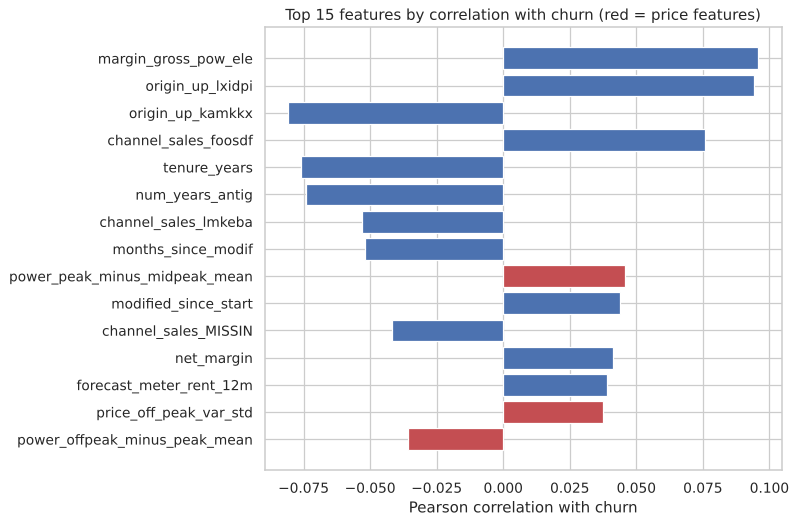

In [9]:
target_corr = df.drop(columns=["id"]).corr()["churn"].drop("churn")
top = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index).head(15)

price_cols = [c for c in price_features.columns if c != "id" and c in df.columns]
fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#C44E52" if c in price_cols else "#4C72B0" for c in top.index]
ax.barh(top.index[::-1], top.values[::-1], color=colors[::-1])
ax.set_title("Top 15 features by correlation with churn (red = price features)")
ax.set_xlabel("Pearson correlation with churn")
plt.tight_layout()

In [10]:
print("Strongest single price-feature correlation:", target_corr[price_cols].abs().max().round(3))
print("Strongest non-price correlation:          ", target_corr.drop(price_cols).abs().max().round(3))

Strongest single price-feature correlation: 0.046
Strongest non-price correlation:           0.096


**Takeaways**
- None of the engineered price features shows more than a weak linear relationship with churn.
- Acquisition campaign, sales channel, tenure and power margin rank highest — all relationship or profitability features, not price features.
- Correlation is only a first filter — Task 4 tests the features jointly with a Random Forest.

In [11]:
df.to_csv("../data/data_for_predictions.csv", index=False)
print("saved data_for_predictions.csv", df.shape)

saved data_for_predictions.csv (14606, 41)
